# Frozen shared ALiBi: field/bond scans and guided GFMC

The main seed501 final won the predefined eight-disorder development comparison
(score 0.291550). Its **single parameter state is frozen across all sizes and
contexts**. This report reads completed records; the progress table distinguishes
partial campaigns from completed stages. Reserved disorders 40000–40007 are unused.

We use $H=\sum K_{ij}Z_iZ_j-\Gamma\sum X_i-h\sum Z_i$ with
$K_{ij}=K(1+0.5u_{ij})$ and matched relative disorder. The full grid is
$\Gamma\in\{0.25,0.5,0.75,1,1.5,2,3\}$,
$h\in\{0,0.15,0.3,0.6,1\}$, $K\in\{0.5,1,2\}$.
Only $K=1$ and the three training anchors have direct training support.
All other contexts measure transfer. Exact states are evaluation references.

GFMC uses the same positive $\psi=\sqrt p$. The 12-spin lookup caches the
**network** exactly. Energy is a mixed estimator; diagonal observables use
four-replica forward walking. Error bars are across independent populations,
and all forward cycles are retained. Projection, population, forward-time,
and branching-cadence dependence must be assessed together. Larger-size
variational measurements and short throughput pilots do not establish
larger-size ground-state accuracy or finite-size scaling.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT=Path('/Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_frozen_scan_v1')
manifest=json.loads((ROOT/'manifest.json').read_text())
assert manifest['checkpoint_sha256']=='5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544'
assert not manifest['reserved_tests_inspected']
display(Markdown('Frozen checkpoint SHA-256: `'+manifest['checkpoint_sha256']+'`'))
data={}
table=['| Stage | Completed records | Expected | Complete |','|---|---:|---:|---|']
for stage in ('benchmark','exact','projection','sampled','gfmc'):
    p=ROOT/(stage+'_summary.json')
    d=json.loads(p.read_text()) if p.exists() else {'rows':[],'completed':False,'expected_rows':'pending'}
    data[stage]=d['rows']
    table.append(f"| {stage} | {len(d['rows'])} | {d['expected_rows']} | {d['completed']} |")
display(Markdown('\n'.join(table)))
if (ROOT/'supervisor.json').exists(): display(json.loads((ROOT/'supervisor.json').read_text()))


Frozen checkpoint SHA-256: `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544`

| Stage | Completed records | Expected | Complete |
|---|---:|---:|---|
| benchmark | 24 | 24 | True |
| exact | 840 | 840 | True |
| projection | 14 | 14 | True |
| sampled | 118 | 630 | False |
| gfmc | 19 | 154 | False |

{'state': 'running',
 'pid': 811801,
 'started_unix': 1793057259.6546009,
 'completed_stages': ['benchmark', 'exact', 'projection'],
 'active': {'gfmc': 811932, 'sampled': 811933},
 'time_cap_hours': 8,
 'updated_unix': 1793057496.157883}

## Exact 12-spin transfer map

Means below use available development disorders; the counts expose partial coverage. Energy errors are per spin. Fidelity and connected-correlation errors carry independent information.

| K | h | Γ | Disorders | Mean fidelity | Minimum fidelity | Mean energy error/N | C RMS error | Absolute χ error |
|---|---|---|---:|---:|---:|---:|---:|---:|
| 0.5 | 0 | 0.25 | 8 | 0.70763 | 0.59321 | 0.016691 | 0.31093 | 2.04830 |
| 0.5 | 0 | 0.5 | 8 | 0.94646 | 0.88790 | 0.006488 | 0.09600 | 0.30323 |
| 0.5 | 0 | 0.75 | 8 | 0.98468 | 0.97649 | 0.003480 | 0.03870 | 0.03659 |
| 0.5 | 0 | 1 | 8 | 0.99390 | 0.99163 | 0.001919 | 0.02228 | 0.01064 |
| 0.5 | 0 | 1.5 | 8 | 0.99801 | 0.99763 | 0.001004 | 0.01145 | 0.00281 |
| 0.5 | 0 | 2 | 8 | 0.99825 | 0.99765 | 0.001254 | 0.00966 | 0.00330 |
| 0.5 | 0 | 3 | 8 | 0.99694 | 0.99652 | 0.003198 | 0.01293 | 0.00501 |
| 0.5 | 0.15 | 0.25 | 8 | 0.53410 | 0.30353 | 0.022196 | 0.21674 | 1.11524 |
| 0.5 | 0.15 | 0.5 | 8 | 0.86414 | 0.59858 | 0.010593 | 0.09155 | 0.33570 |
| 0.5 | 0.15 | 0.75 | 8 | 0.97236 | 0.93371 | 0.004824 | 0.03751 | 0.03351 |
| 0.5 | 0.15 | 1 | 8 | 0.98990 | 0.98493 | 0.002642 | 0.02270 | 0.00667 |
| 0.5 | 0.15 | 1.5 | 8 | 0.99613 | 0.99509 | 0.001478 | 0.01193 | 0.00269 |
| 0.5 | 0.15 | 2 | 8 | 0.99687 | 0.99576 | 0.001775 | 0.00989 | 0.00225 |
| 0.5 | 0.15 | 3 | 8 | 0.99489 | 0.99422 | 0.004450 | 0.01269 | 0.00243 |
| 0.5 | 0.3 | 0.25 | 8 | 0.51194 | 0.17869 | 0.026566 | 0.19844 | 0.94547 |
| 0.5 | 0.3 | 0.5 | 8 | 0.80202 | 0.56771 | 0.015010 | 0.10745 | 0.43419 |
| 0.5 | 0.3 | 0.75 | 8 | 0.94780 | 0.83798 | 0.007039 | 0.04053 | 0.08343 |
| 0.5 | 0.3 | 1 | 8 | 0.98170 | 0.96636 | 0.004122 | 0.02409 | 0.02055 |
| 0.5 | 0.3 | 1.5 | 8 | 0.99303 | 0.99177 | 0.002417 | 0.01322 | 0.00973 |
| 0.5 | 0.3 | 2 | 8 | 0.99578 | 0.99448 | 0.002166 | 0.01068 | 0.00719 |
| 0.5 | 0.3 | 3 | 8 | 0.99598 | 0.99526 | 0.003671 | 0.01263 | 0.00519 |
| 0.5 | 0.6 | 0.25 | 8 | 0.52211 | 0.04624 | 0.034845 | 0.18025 | 0.68151 |
| 0.5 | 0.6 | 0.5 | 8 | 0.69005 | 0.45589 | 0.026321 | 0.13221 | 0.64112 |
| 0.5 | 0.6 | 0.75 | 8 | 0.87384 | 0.70365 | 0.016814 | 0.05798 | 0.20191 |
| 0.5 | 0.6 | 1 | 8 | 0.94192 | 0.90242 | 0.012237 | 0.03304 | 0.08378 |
| 0.5 | 0.6 | 1.5 | 8 | 0.97273 | 0.96847 | 0.009345 | 0.01889 | 0.04269 |
| 0.5 | 0.6 | 2 | 8 | 0.98294 | 0.97999 | 0.007972 | 0.01434 | 0.03076 |
| 0.5 | 0.6 | 3 | 8 | 0.99095 | 0.98950 | 0.006902 | 0.01351 | 0.01955 |
| 0.5 | 1 | 0.25 | 8 | 0.42793 | 0.03564 | 0.044443 | 0.18698 | 0.76363 |
| 0.5 | 1 | 0.5 | 8 | 0.61670 | 0.36058 | 0.041482 | 0.14821 | 0.63336 |
| 0.5 | 1 | 0.75 | 8 | 0.74984 | 0.66304 | 0.041758 | 0.08458 | 0.27522 |
| 0.5 | 1 | 1 | 8 | 0.83835 | 0.80557 | 0.037716 | 0.05641 | 0.17668 |
| 0.5 | 1 | 1.5 | 8 | 0.91030 | 0.89764 | 0.031994 | 0.03338 | 0.11576 |
| 0.5 | 1 | 2 | 8 | 0.94067 | 0.93282 | 0.027898 | 0.02374 | 0.08711 |
| 0.5 | 1 | 3 | 8 | 0.96854 | 0.96488 | 0.021802 | 0.01714 | 0.05583 |
| 1 | 0 | 0.25 | 8 | 0.27416 | 0.10079 | 0.055395 | 0.69474 | 3.36794 |
| 1 | 0 | 0.5 | 8 | 0.82334 | 0.65918 | 0.017269 | 0.23986 | 1.05015 |
| 1 | 0 | 0.75 | 8 | 0.92272 | 0.83318 | 0.012953 | 0.12650 | 0.63738 |
| 1 | 0 | 1 | 8 | 0.96084 | 0.90025 | 0.008809 | 0.08348 | 0.29161 |
| 1 | 0 | 1.5 | 8 | 0.99064 | 0.98194 | 0.003771 | 0.03269 | 0.05887 |
| 1 | 0 | 2 | 8 | 0.99670 | 0.99502 | 0.001884 | 0.01763 | 0.02232 |
| 1 | 0 | 3 | 8 | 0.99764 | 0.99690 | 0.002402 | 0.01230 | 0.00249 |
| 1 | 0.15 | 0.25 | 8 | 0.23139 | 0.04283 | 0.061901 | 0.19770 | 0.79270 |
| 1 | 0.15 | 0.5 | 8 | 0.64788 | 0.20525 | 0.021125 | 0.16844 | 0.70868 |
| 1 | 0.15 | 0.75 | 8 | 0.85444 | 0.66054 | 0.016889 | 0.13650 | 0.55889 |
| 1 | 0.15 | 1 | 8 | 0.92625 | 0.71617 | 0.011359 | 0.07603 | 0.26976 |
| 1 | 0.15 | 1.5 | 8 | 0.98846 | 0.97433 | 0.004325 | 0.03158 | 0.05082 |
| 1 | 0.15 | 2 | 8 | 0.99585 | 0.99405 | 0.002279 | 0.01726 | 0.02244 |
| 1 | 0.15 | 3 | 8 | 0.99616 | 0.99578 | 0.003387 | 0.01171 | 0.00416 |
| 1 | 0.3 | 0.25 | 8 | 0.25591 | 0.05947 | 0.067509 | 0.19150 | 0.65989 |
| 1 | 0.3 | 0.5 | 8 | 0.70185 | 0.47562 | 0.023605 | 0.16311 | 0.68754 |
| 1 | 0.3 | 0.75 | 8 | 0.82333 | 0.61667 | 0.019830 | 0.13892 | 0.58732 |
| 1 | 0.3 | 1 | 8 | 0.90074 | 0.66659 | 0.013819 | 0.07981 | 0.30898 |
| 1 | 0.3 | 1.5 | 8 | 0.98369 | 0.94542 | 0.004715 | 0.02935 | 0.04561 |
| 1 | 0.3 | 2 | 8 | 0.99549 | 0.99154 | 0.002197 | 0.01663 | 0.01744 |
| 1 | 0.3 | 3 | 8 | 0.99698 | 0.99662 | 0.002630 | 0.01113 | 0.00286 |
| 1 | 0.6 | 0.25 | 8 | 0.29165 | 0.00685 | 0.082431 | 0.16613 | 0.62652 |
| 1 | 0.6 | 0.5 | 8 | 0.65133 | 0.30328 | 0.030207 | 0.15403 | 0.58063 |
| 1 | 0.6 | 0.75 | 8 | 0.75275 | 0.59391 | 0.027684 | 0.15034 | 0.73604 |
| 1 | 0.6 | 1 | 8 | 0.84852 | 0.68246 | 0.021114 | 0.09511 | 0.40173 |
| 1 | 0.6 | 1.5 | 8 | 0.96372 | 0.86028 | 0.007705 | 0.02957 | 0.06539 |
| 1 | 0.6 | 2 | 8 | 0.99005 | 0.97670 | 0.003872 | 0.01574 | 0.00855 |
| 1 | 0.6 | 3 | 8 | 0.99570 | 0.99441 | 0.003268 | 0.01042 | 0.00469 |
| 1 | 1 | 0.25 | 8 | 0.31974 | 0.00473 | 0.103629 | 0.16754 | 0.66315 |
| 1 | 1 | 0.5 | 8 | 0.60033 | 0.11036 | 0.042730 | 0.17856 | 0.71635 |
| 1 | 1 | 0.75 | 8 | 0.66977 | 0.39656 | 0.039426 | 0.16884 | 0.76691 |
| 1 | 1 | 1 | 8 | 0.77430 | 0.56795 | 0.034072 | 0.11512 | 0.55569 |
| 1 | 1 | 1.5 | 8 | 0.92618 | 0.77759 | 0.016823 | 0.03910 | 0.14405 |
| 1 | 1 | 2 | 8 | 0.97213 | 0.94393 | 0.010954 | 0.01895 | 0.04373 |
| 1 | 1 | 3 | 8 | 0.98720 | 0.98430 | 0.009130 | 0.01178 | 0.02417 |
| 2 | 0 | 0.25 | 8 | 0.10550 | 0.00588 | 0.170869 | 0.92093 | 3.29330 |
| 2 | 0 | 0.5 | 8 | 0.28595 | 0.11884 | 0.107531 | 0.68509 | 3.10134 |
| 2 | 0 | 0.75 | 8 | 0.56088 | 0.28790 | 0.063611 | 0.46540 | 1.74255 |
| 2 | 0 | 1 | 8 | 0.67956 | 0.41536 | 0.061905 | 0.35786 | 1.25438 |
| 2 | 0 | 1.5 | 8 | 0.84243 | 0.71851 | 0.057888 | 0.18620 | 0.35329 |
| 2 | 0 | 2 | 8 | 0.93834 | 0.89116 | 0.034408 | 0.09170 | 0.09675 |
| 2 | 0 | 3 | 8 | 0.98525 | 0.97287 | 0.014027 | 0.03556 | 0.01233 |
| 2 | 0.15 | 0.25 | 8 | 0.09998 | 0.00008 | 0.177005 | 0.16039 | 0.52460 |
| 2 | 0.15 | 0.5 | 8 | 0.20723 | 0.05113 | 0.114857 | 0.19467 | 0.74963 |
| 2 | 0.15 | 0.75 | 8 | 0.39952 | 0.05686 | 0.069346 | 0.17931 | 0.67897 |
| 2 | 0.15 | 1 | 8 | 0.50484 | 0.10748 | 0.066837 | 0.19174 | 0.86085 |
| 2 | 0.15 | 1.5 | 8 | 0.77100 | 0.63110 | 0.064647 | 0.16548 | 0.57563 |
| 2 | 0.15 | 2 | 8 | 0.91136 | 0.83785 | 0.039310 | 0.08899 | 0.18953 |
| 2 | 0.15 | 3 | 8 | 0.98259 | 0.97021 | 0.015313 | 0.03465 | 0.01609 |
| 2 | 0.3 | 0.25 | 8 | 0.10317 | 0.00006 | 0.183103 | 0.14883 | 0.46692 |
| 2 | 0.3 | 0.5 | 8 | 0.21438 | 0.03918 | 0.121286 | 0.19190 | 0.72085 |
| 2 | 0.3 | 0.75 | 8 | 0.39815 | 0.06142 | 0.073153 | 0.16250 | 0.54862 |
| 2 | 0.3 | 1 | 8 | 0.48795 | 0.11465 | 0.068577 | 0.16684 | 0.66122 |
| 2 | 0.3 | 1.5 | 8 | 0.76030 | 0.61018 | 0.065415 | 0.15914 | 0.51376 |
| 2 | 0.3 | 2 | 8 | 0.90322 | 0.80202 | 0.040215 | 0.09565 | 0.24722 |
| 2 | 0.3 | 3 | 8 | 0.98321 | 0.97032 | 0.014889 | 0.03346 | 0.01065 |
| 2 | 0.6 | 0.25 | 8 | 0.11803 | 0.00195 | 0.196569 | 0.13584 | 0.42088 |
| 2 | 0.6 | 0.5 | 8 | 0.23299 | 0.03433 | 0.133941 | 0.19719 | 0.67899 |
| 2 | 0.6 | 0.75 | 8 | 0.41484 | 0.07280 | 0.079207 | 0.17021 | 0.53318 |
| 2 | 0.6 | 1 | 8 | 0.56630 | 0.21452 | 0.071862 | 0.17069 | 0.72777 |
| 2 | 0.6 | 1.5 | 8 | 0.73650 | 0.57151 | 0.068443 | 0.14804 | 0.51366 |
| 2 | 0.6 | 2 | 8 | 0.88728 | 0.78254 | 0.043631 | 0.10146 | 0.32067 |
| 2 | 0.6 | 3 | 8 | 0.98071 | 0.95458 | 0.015385 | 0.03136 | 0.02936 |
| 2 | 1 | 0.25 | 8 | 0.13391 | 0.00044 | 0.222282 | 0.13085 | 0.42943 |
| 2 | 1 | 0.5 | 8 | 0.23996 | 0.00930 | 0.156249 | 0.18345 | 0.73142 |
| 2 | 1 | 0.75 | 8 | 0.47508 | 0.07465 | 0.090647 | 0.17176 | 0.61635 |
| 2 | 1 | 1 | 8 | 0.55941 | 0.15602 | 0.077908 | 0.15096 | 0.48309 |
| 2 | 1 | 1.5 | 8 | 0.70697 | 0.48631 | 0.073613 | 0.13801 | 0.51391 |
| 2 | 1 | 2 | 8 | 0.86326 | 0.79447 | 0.050274 | 0.10487 | 0.37022 |
| 2 | 1 | 3 | 8 | 0.97159 | 0.91701 | 0.018770 | 0.03110 | 0.06858 |

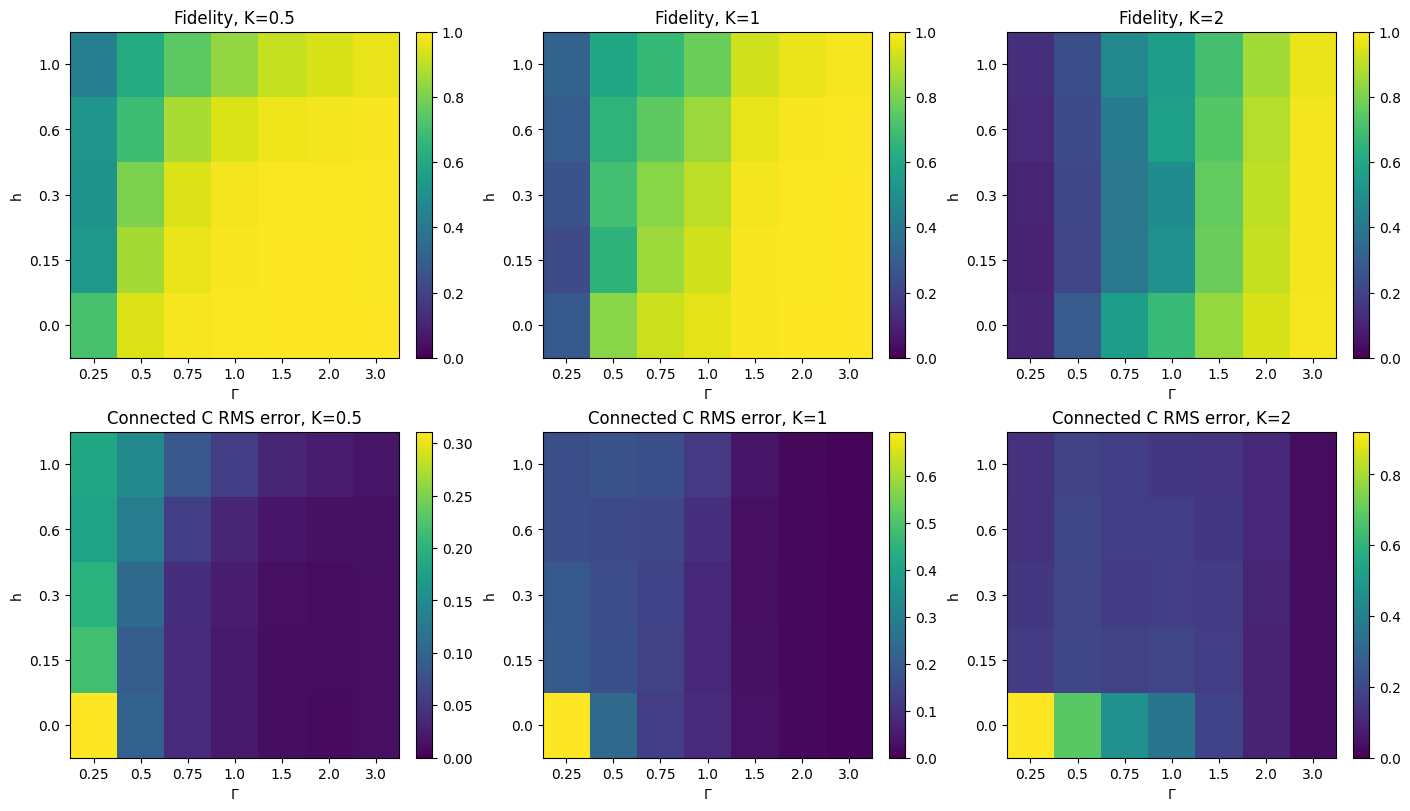

In [2]:
rows=data['exact']
table=['| K | h | Γ | Disorders | Mean fidelity | Minimum fidelity | Mean energy error/N | C RMS error | Absolute χ error |', '|---|---|---|---:|---:|---:|---:|---:|---:|']
for K in manifest['K']:
    for h in manifest['h']:
        for g in manifest['gamma']:
            group=[r for r in rows if (r['K'],r['h'],r['gamma'])==(K,h,g)]
            if not group: continue
            table.append(f"| {K:g} | {h:g} | {g:g} | {len(group)} | {np.mean([r['fidelity'] for r in group]):.5f} | {min(r['fidelity'] for r in group):.5f} | {np.mean([r['energy_error_per_spin'] for r in group]):.6f} | {np.mean([r['connected_correlation_rms_error'] for r in group]):.5f} | {np.mean([abs(r['chi_connected']-r['exact_chi']) for r in group]):.5f} |")
display(Markdown('\n'.join(table)))
if rows:
    fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
    for col,K in enumerate(manifest['K']):
        for row,metric,title in [(0,'fidelity','Fidelity'),(1,'connected_correlation_rms_error','Connected C RMS error')]:
            array=np.full((len(manifest['h']),len(manifest['gamma'])),np.nan)
            for j,h in enumerate(manifest['h']):
                for i,g in enumerate(manifest['gamma']):
                    group=[v[metric] for v in rows if (v['K'],v['h'],v['gamma'])==(K,h,g)]
                    if group: array[j,i]=np.mean(group)
            ax=axes[row,col]
            im=ax.imshow(array,origin='lower',aspect='auto',vmin=0,vmax=1 if row==0 else None)
            ax.set_xticks(range(len(manifest['gamma'])),manifest['gamma'])
            ax.set_yticks(range(len(manifest['h'])),manifest['h'])
            ax.set(xlabel='Γ',ylabel='h',title=f'{title}, K={K:g}')
            fig.colorbar(im,ax=ax)
    fig.savefig(ROOT/'exact_transfer_maps.png',dpi=160)
    plt.show()


## Common energy scaling

For matched disorder, $H(K,\Gamma,h)=K H(1,\Gamma/K,h/K)$, so exact
ground-state observables are invariant at fixed field ratios. Network fidelity
between two commonly scaled Hamiltonians tests learned scale response; its
parameters are unchanged. Only pairs present in the executed grid are compared.


In [3]:
lookup={(r['sample_id'],r['gamma'],r['h'],r['K']):r for r in rows}
scaling=[]
for r in rows:
    if r['K']==1: continue
    other=lookup.get((r['sample_id'],r['gamma']/r['K'],r['h']/r['K'],1.))
    if other is None: continue
    def cache(row):
        name=f"L2_s{row['sample_id']}_g{row['gamma']:g}_h{row['h']:g}_K{row['K']:g}".replace('.','p')
        with np.load(ROOT/'exact'/(name+'.npz')) as d: return np.exp(d['logs']),d['exact'].copy()
    a,ea=cache(r); b,eb=cache(other)
    scaling.append(dict(K=r['K'],h=r['h'],gamma=r['gamma'],sample_id=r['sample_id'],
                        network_scale_fidelity=float((a@b)**2),exact_scale_fidelity=float((ea@eb)**2),
                        energy_scale_residual=abs(r['exact_energy']/r['K']-other['exact_energy'])))
if scaling:
    display(Markdown(f"Common-scale checks: **{len(scaling)}** pairs; minimum exact scale fidelity **{min(r['exact_scale_fidelity'] for r in scaling):.12f}**; maximum energy scaling residual **{max(r['energy_scale_residual'] for r in scaling):.3g}**; mean network scale fidelity **{np.mean([r['network_scale_fidelity'] for r in scaling]):.6f}** (minimum **{min(r['network_scale_fidelity'] for r in scaling):.6f}**)."))
else: display(Markdown('No completed common-scale pairs yet.'))


Common-scale checks: **240** pairs; minimum exact scale fidelity **1.000000000000**; maximum energy scaling residual **0**; mean network scale fidelity **0.939836** (minimum **0.647781**).

## Exact projection reference

These curves establish 12-spin time dependence without population or ancestry bias. The pure projected energy and GFMC mixed-energy reference are recorded separately.

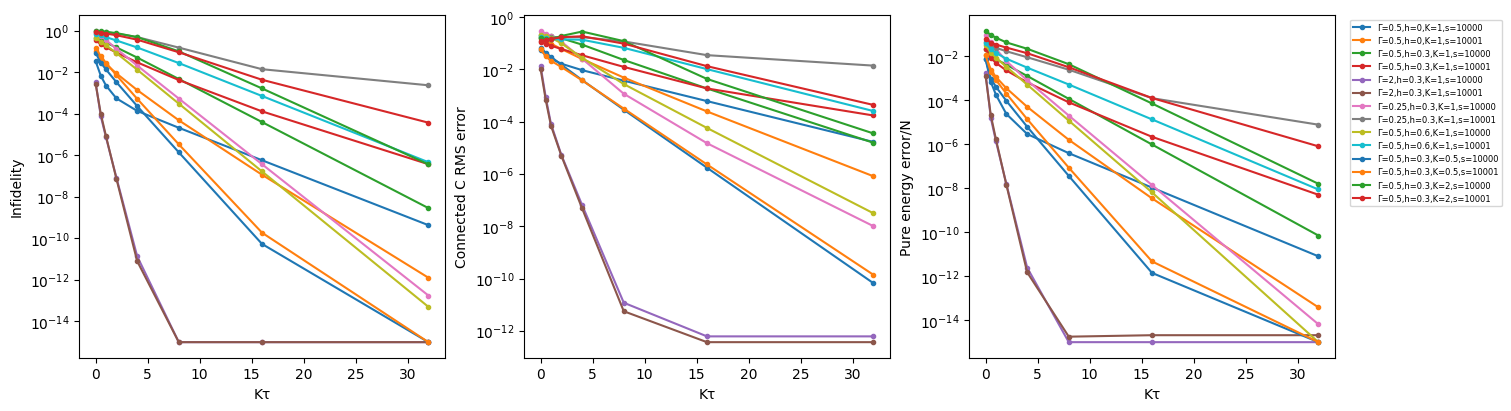

In [4]:
projected=data['projection']
if projected:
    fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
    for r in projected:
        t=r['trajectory']; x=[v['Ktau'] for v in t]
        label=f"Γ={r['gamma']:g},h={r['h']:g},K={r['K']:g},s={r['sample_id']}"
        for ax,metric in zip(axes,['fidelity','connected_correlation_rms_error','energy_error_per_spin']):
            y=[1-v[metric] if metric=='fidelity' else v[metric] for v in t]
            ax.semilogy(x,np.maximum(y,1e-15),'.-',label=label)
    for ax,title in zip(axes,['Infidelity','Connected C RMS error','Pure energy error/N']): ax.set(xlabel='Kτ',ylabel=title)
    axes[-1].legend(fontsize=6,bbox_to_anchor=(1.03,1))
    fig.savefig(ROOT/'exact_projection_scan.png',dpi=160)
    plt.show()
else: display(Markdown('Exact projection stage pending.'))


## Measured direct-guide cost

Every rate call evaluates all single-spin flip ratios. Timings include GPU synchronization; these determine feasible larger-size projection budgets.

In [5]:
cost=data['benchmark']
table=['| L | N | h | States | Sample seconds | All-flip seconds | Mean escape rate |','|---|---:|---:|---:|---:|---:|---:|']
for r in cost:
    table.append(f"| {r['L']} | {3*r['L']**2} | {r['h']:g} | {r['states']} | {r['sample_seconds']:.4f} | {r['flip_ratio_seconds']:.4f} | {r['mean_escape_rate']:.3f} |")
display(Markdown('\n'.join(table)))
table=['| L | h | Walkers / replicas | Physical time | Wall seconds | Weight ESS |','|---|---:|---|---:|---:|---:|']
for p in sorted(ROOT.glob('direct_step*.json')):
    r=json.loads(p.read_text())
    table.append(f"| {r['L']} | {r['h']:g} | {r['walkers']} / {r['replicas']} | {r['tau']} | {r['seconds']:.3f} | {r['weight_ess']:.2f} |")
display(Markdown('\n'.join(table)))


| L | N | h | States | Sample seconds | All-flip seconds | Mean escape rate |
|---|---:|---:|---:|---:|---:|---:|
| 2 | 12 | 0 | 8 | 0.2342 | 0.0082 | 2.763 |
| 2 | 12 | 0 | 32 | 0.0103 | 0.0093 | 3.227 |
| 2 | 12 | 0 | 128 | 0.0082 | 0.0227 | 2.960 |
| 2 | 12 | 0.3 | 8 | 0.0078 | 0.0040 | 2.672 |
| 2 | 12 | 0.3 | 32 | 0.0080 | 0.0048 | 3.025 |
| 2 | 12 | 0.3 | 128 | 0.0103 | 0.0115 | 2.830 |
| 4 | 48 | 0 | 8 | 0.0334 | 0.0150 | 11.220 |
| 4 | 48 | 0 | 32 | 0.0304 | 0.0444 | 12.494 |
| 4 | 48 | 0 | 128 | 0.0493 | 0.1651 | 11.248 |
| 4 | 48 | 0.3 | 8 | 0.0294 | 0.0078 | 10.714 |
| 4 | 48 | 0.3 | 32 | 0.0295 | 0.0223 | 11.797 |
| 4 | 48 | 0.3 | 128 | 0.0472 | 0.0826 | 10.476 |
| 6 | 108 | 0 | 8 | 0.0787 | 0.0695 | 24.202 |
| 6 | 108 | 0 | 32 | 0.0848 | 0.2753 | 26.924 |
| 6 | 108 | 0 | 128 | 0.2214 | 1.0963 | 25.548 |
| 6 | 108 | 0.3 | 8 | 0.0669 | 0.0352 | 24.452 |
| 6 | 108 | 0.3 | 32 | 0.0849 | 0.1380 | 25.205 |
| 6 | 108 | 0.3 | 128 | 0.2211 | 0.5486 | 24.275 |
| 8 | 192 | 0 | 8 | 0.1187 | 0.1960 | 49.124 |
| 8 | 192 | 0 | 32 | 0.2126 | 0.8681 | 46.354 |
| 8 | 192 | 0 | 128 | 0.5680 | 3.4610 | 47.215 |
| 8 | 192 | 0.3 | 8 | 0.1154 | 0.0985 | 45.038 |
| 8 | 192 | 0.3 | 32 | 0.2124 | 0.4351 | 46.032 |
| 8 | 192 | 0.3 | 128 | 0.5686 | 1.7305 | 45.618 |

| L | h | Walkers / replicas | Physical time | Wall seconds | Weight ESS |
|---|---:|---|---:|---:|---:|
| 2 | 0.3 | 16 / 4 | 0.02 | 0.027 | 15.99 |
| 2 | 0 | 16 / 4 | 0.02 | 0.045 | 16.00 |
| 4 | 0.3 | 16 / 4 | 0.02 | 0.164 | 13.06 |
| 4 | 0 | 16 / 4 | 0.02 | 0.292 | 14.45 |
| 6 | 0.3 | 16 / 4 | 0.02 | 1.219 | 15.90 |
| 6 | 0 | 16 / 4 | 0.02 | 2.300 | 15.80 |
| 8 | 0.3 | 16 / 4 | 0.02 | 5.462 | 15.82 |
| 8 | 0 | 16 / 4 | 0.02 | 10.381 | 15.81 |

## Sampled larger-size variational measurements

Errors shown here are Monte Carlo standard errors across fresh direct-sampling batches. They do not include wavefunction bias. Only two disorder realizations enter each point; this is a scan, not a disorder-converged phase boundary.

| L | Points | Mean energy/N | Minimum χ | Maximum χ | Total seconds |
|---|---:|---:|---:|---:|---:|
| 4 | 40 | -1.107502 | 0.69368 | 12.78792 | 74.9 |
| 6 | 39 | -1.091485 | 0.93887 | 8.44690 | 389.4 |
| 8 | 39 | -1.077030 | 1.22257 | 10.27543 | 1117.6 |

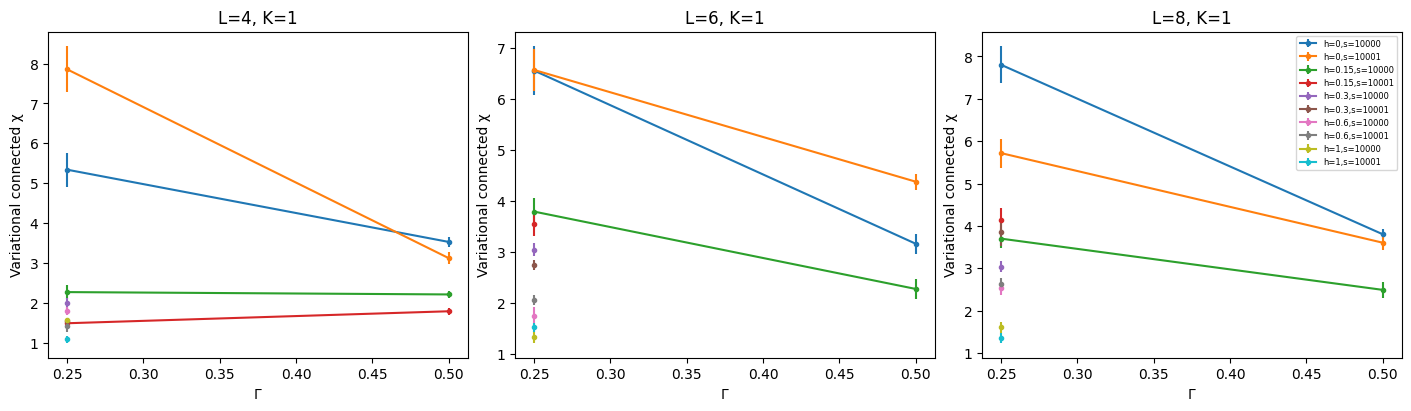

In [6]:
sampled=data['sampled']
table=['| L | Points | Mean energy/N | Minimum χ | Maximum χ | Total seconds |','|---|---:|---:|---:|---:|---:|']
for L in (4,6,8):
    group=[r for r in sampled if r['L']==L]
    if group: table.append(f"| {L} | {len(group)} | {np.mean([r['energy']['mean']/(3*L*L) for r in group]):.6f} | {min(r['chi_connected']['mean'] for r in group):.5f} | {max(r['chi_connected']['mean'] for r in group):.5f} | {sum(r['seconds'] for r in group):.1f} |")
display(Markdown('\n'.join(table)))
if sampled:
    fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
    for ax,L in zip(axes,(4,6,8)):
        for h in manifest['h']:
            group=[r for r in sampled if r['L']==L and r['K']==1. and r['h']==h]
            for sid in manifest['sampled_ids']:
                values=sorted([r for r in group if r['sample_id']==sid],key=lambda v:v['gamma'])
                if values: ax.errorbar([v['gamma'] for v in values],[v['chi_connected']['mean'] for v in values],yerr=[v['chi_connected']['se'] for v in values],marker='.',label=f'h={h:g},s={sid}')
        ax.set(xlabel='Γ',ylabel='Variational connected χ',title=f'L={L}, K=1')
    axes[-1].legend(fontsize=6)
    fig.savefig(ROOT/'sampled_variational_scan.png',dpi=160)
    plt.show()


## Selected-guide stochastic GFMC

Population dependence is compared at fixed physical context. The largest population and forward time also receive an equilibration-time check and a finer branching-cadence check. Low ancestry ESS is reported without dropping cycles.

| Γ | h | K | Disorder | W | Kτ forward | Kτ branch | Kτ equil | E−E₀ | χ ± SE | Exact χ | Min ancestry ESS | Largest lineage |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.5 | 0 | 1 | 10000 | 512 | 2 | 0.1 | 16 | -0.00323 | 2.61487 ± 0.19594 | 2.62544 | 81.92 | 0.080 |
| 0.5 | 0 | 1 | 10000 | 512 | 8 | 0.1 | 16 | -0.00323 | 2.54209 ± 0.10539 | 2.62544 | 26.10 | 0.129 |
| 0.5 | 0 | 1 | 10000 | 512 | 16 | 0.1 | 16 | -0.00323 | 2.70611 ± 0.04399 | 2.62544 | 14.31 | 0.203 |
| 0.5 | 0 | 1 | 10000 | 2048 | 2 | 0.1 | 16 | -0.00037 | 2.59798 ± 0.03565 | 2.62544 | 402.52 | 0.027 |
| 0.5 | 0 | 1 | 10000 | 2048 | 8 | 0.1 | 16 | -0.00037 | 2.59612 ± 0.07558 | 2.62544 | 124.05 | 0.042 |
| 0.5 | 0 | 1 | 10000 | 2048 | 16 | 0.1 | 16 | -0.00037 | 2.63090 ± 0.09451 | 2.62544 | 52.75 | 0.098 |
| 0.5 | 0 | 1 | 10000 | 8192 | 2 | 0.1 | 16 | -0.00082 | 2.61740 ± 0.08226 | 2.62544 | 1675.54 | 0.012 |
| 0.5 | 0 | 1 | 10000 | 8192 | 8 | 0.1 | 16 | -0.00082 | 2.54742 ± 0.04381 | 2.62544 | 558.25 | 0.012 |
| 0.5 | 0 | 1 | 10000 | 8192 | 16 | 0.1 | 16 | -0.00082 | 2.56458 ± 0.04058 | 2.62544 | 293.01 | 0.023 |
| 0.5 | 0 | 1 | 10000 | 8192 | 16 | 0.05 | 16 | -0.00084 | 2.64840 ± 0.05588 | 2.62544 | 261.74 | 0.021 |
| 0.5 | 0 | 1 | 10000 | 8192 | 16 | 0.1 | 8 | 0.00199 | 2.56218 ± 0.05014 | 2.62544 | 281.49 | 0.022 |
| 0.5 | 0 | 1 | 10001 | 512 | 2 | 0.1 | 16 | 0.00366 | 2.16043 ± 0.11114 | 2.50904 | 64.73 | 0.092 |
| 0.5 | 0 | 1 | 10001 | 512 | 8 | 0.1 | 16 | 0.00366 | 2.41918 ± 0.15356 | 2.50904 | 11.68 | 0.254 |
| 0.5 | 0 | 1 | 10001 | 512 | 16 | 0.1 | 16 | 0.00366 | 2.29508 ± 0.17611 | 2.50904 | 7.24 | 0.328 |
| 0.5 | 0 | 1 | 10001 | 2048 | 2 | 0.1 | 16 | 0.00219 | 2.33582 ± 0.07993 | 2.50904 | 161.27 | 0.059 |
| 0.5 | 0 | 1 | 10001 | 2048 | 8 | 0.1 | 16 | 0.00219 | 2.42984 ± 0.07122 | 2.50904 | 58.69 | 0.079 |
| 0.5 | 0 | 1 | 10001 | 2048 | 16 | 0.1 | 16 | 0.00219 | 2.45324 ± 0.06984 | 2.50904 | 22.11 | 0.136 |
| 0.5 | 0 | 1 | 10001 | 8192 | 2 | 0.1 | 16 | -0.00028 | 2.43944 ± 0.05313 | 2.50904 | 1183.58 | 0.017 |
| 0.5 | 0 | 1 | 10001 | 8192 | 8 | 0.1 | 16 | -0.00028 | 2.47760 ± 0.04313 | 2.50904 | 263.08 | 0.028 |

/var/folders/pl/l9f5xt416qq5qz_7wfhm_94c0000gn/T/ipykernel_69959/3552785367.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0,-1].legend(fontsize=7)


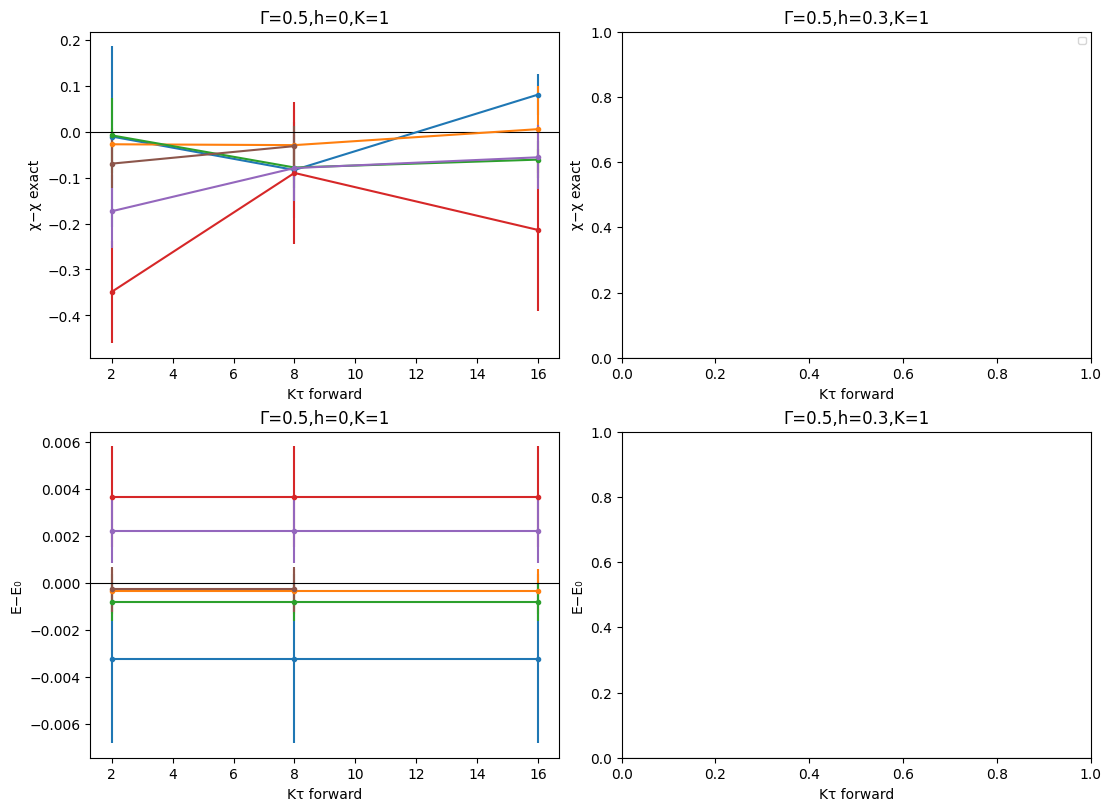

In [7]:
gfmc=data['gfmc']
table=['| Γ | h | K | Disorder | W | Kτ forward | Kτ branch | Kτ equil | E−E₀ | χ ± SE | Exact χ | Min ancestry ESS | Largest lineage |','|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|']
for r in gfmc:
    e=r['observables']['energy']; c=r['observables']['chi_connected']
    table.append(f"| {r['gamma']:g} | {r['h']:g} | {r['K']:g} | {r['sample_id']} | {r['walkers']} | {r['forward_Ktau']:g} | {r['branch_Ktau']:g} | {r['equilibration_Ktau']:g} | {e['bias']:.5f} | {c['mean']:.5f} ± {c['se']:.5f} | {c['exact']:.5f} | {r['min_descendant_ess']:.2f} | {r['max_largest_lineage']:.3f} |")
display(Markdown('\n'.join(table)))
if gfmc:
    fig,axes=plt.subplots(2,2,figsize=(11,8),constrained_layout=True)
    for col,h in enumerate((0.,.3)):
        for sid in (10000,10001):
            for W in (512,2048,8192):
                values=sorted([r for r in gfmc if (r['gamma'],r['h'],r['K'],r['sample_id'],r['walkers'],r['branch_Ktau'],r['equilibration_Ktau'])==(.5,h,1.,sid,W,.1,16.)],key=lambda v:v['forward_Ktau'])
                if not values: continue
                for ax,metric in zip(axes[:,col],['chi_connected','energy']):
                    ax.errorbar([v['forward_Ktau'] for v in values],[v['observables'][metric]['bias'] for v in values],yerr=[v['observables'][metric]['se'] for v in values],marker='.',label=f's={sid},W={W}')
        for ax,metric in zip(axes[:,col],['χ−χ exact','E−E₀']):
            ax.axhline(0,color='k',lw=.8); ax.set(xlabel='Kτ forward',ylabel=metric,title=f'Γ=0.5,h={h:g},K=1')
    axes[0,-1].legend(fontsize=7)
    fig.savefig(ROOT/'selected_guide_gfmc_convergence.png',dpi=160)
    plt.show()


## Direct-network 48-spin GFMC pilot

These runs use network inference during every continuous-time trajectory, with exact memoization of repeated states. Small walker populations and short projection times are pilot settings. They establish execution and measured cost; convergence remains to be demonstrated.

In [8]:
direct_paths=[Path(p) for p in ['/Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_frozen_scan_v1/direct_preview', '/Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_frozen_scan_v1/direct_pilot']]
table=['| Run | Disorder | h | W | Equilibration | Forward | Branch | E/N ± SE | χ ± SE | Min ancestry ESS | Largest lineage | Seconds |','|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|']
for directory in direct_paths:
    p=directory/'summary.json'
    if not p.exists():
        display(Markdown(directory.name+': no completed group of independent populations yet.'))
        continue
    d=json.loads(p.read_text())
    assert d['manifest']['checkpoint_sha256']==manifest['checkpoint_sha256']
    display(Markdown(directory.name+f": {len(d['rows'])} completed settings; campaign complete={d['completed']}."))
    for r in d['rows']:
        e=r['observables']['energy']; c=r['observables']['chi_connected']
        table.append(f"| {directory.name} | {r['sample_id']} | {r['h']:g} | {r['walkers']} | {r['equilibration_time']:g} | {r['tau_forward']:g} | {r['tau_block']:g} | {e['mean']/48:.6f} ± {e['se']/48:.6f} | {c['mean']:.5f} ± {c['se']:.5f} | {r['min_descendant_ess']:.2f} | {r['max_largest_lineage']:.3f} | {r['seconds']:.1f} |")
display(Markdown('\n'.join(table)))


direct_preview: 1 completed settings; campaign complete=True.

direct_pilot: no completed group of independent populations yet.

| Run | Disorder | h | W | Equilibration | Forward | Branch | E/N ± SE | χ ± SE | Min ancestry ESS | Largest lineage | Seconds |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| direct_preview | 10000 | 0.3 | 32 | 1 | 0.5 | 0.1 | -1.123262 ± 0.003046 | 1.34001 ± 0.47390 | 2.44 | 0.625 | 35.5 |

## Interpretation limits

The selected guide is the best measured shared candidate under the frozen
development criterion. Low-field fidelity is uneven. Transfer to new field
and bond scales must be read from the scan above. Exact 12-spin projection
can converge while finite-population susceptibility remains biased; energy
agreement alone is insufficient. Ground-state claims at larger sizes require
their own population, projection, forward-time, and cadence checks.
